# Compulsory Assignement 4, Dat200
**Group4** Lasse Lindholm & Brage Bromset Bestvold

# Imports

In [10]:
# for preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# our 4 different classifers to test
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

from sklearn.preprocessing import OneHotEncoder

# for feature selection
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline      import make_pipeline
from sklearn.decomposition import PCA

# To stop warnings from
import warnings
warnings.filterwarnings("ignore", category=Warning, module="sklearn")

# Reading/Loading the data

In [2]:
train = pd.read_csv("trainCA4DAT200.csv")
test = pd.read_csv("testCA4DAT200.csv")
train.head()

,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


# Data Exploration


In [3]:

categorical_data = ["State","AreaCode", "InternationalPlan", "VoiceMailPlan"]


ohe = OneHotEncoder(sparse_output=False)
data = ohe.fit_transform(train[categorical_data])



data = pd.DataFrame(
    data,
    columns=ohe.get_feature_names_out(categorical_data),
    index=train.index
)



train = pd.concat([
    train.drop(columns=categorical_data),
    data],
    axis=1
)

train.head()


,CustomerId,AccountLength,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,...,State_WI,State_WV,State_WY,AreaCode_408,AreaCode_415,AreaCode_510,InternationalPlan_no,InternationalPlan_yes,VoiceMailPlan_no,VoiceMailPlan_yes
0,952920,87,0,223.2,109,37.94,127.5,86,10.84,289.3,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
1,895150,114,28,225.8,94,38.39,193.0,117,16.41,232.4,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,636987,55,0,180.1,77,30.62,235.5,98,20.02,169.4,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,538188,100,0,68.5,110,11.65,337.1,115,28.65,205.2,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
4,947531,74,46,277.7,109,47.21,270.0,114,22.95,165.3,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


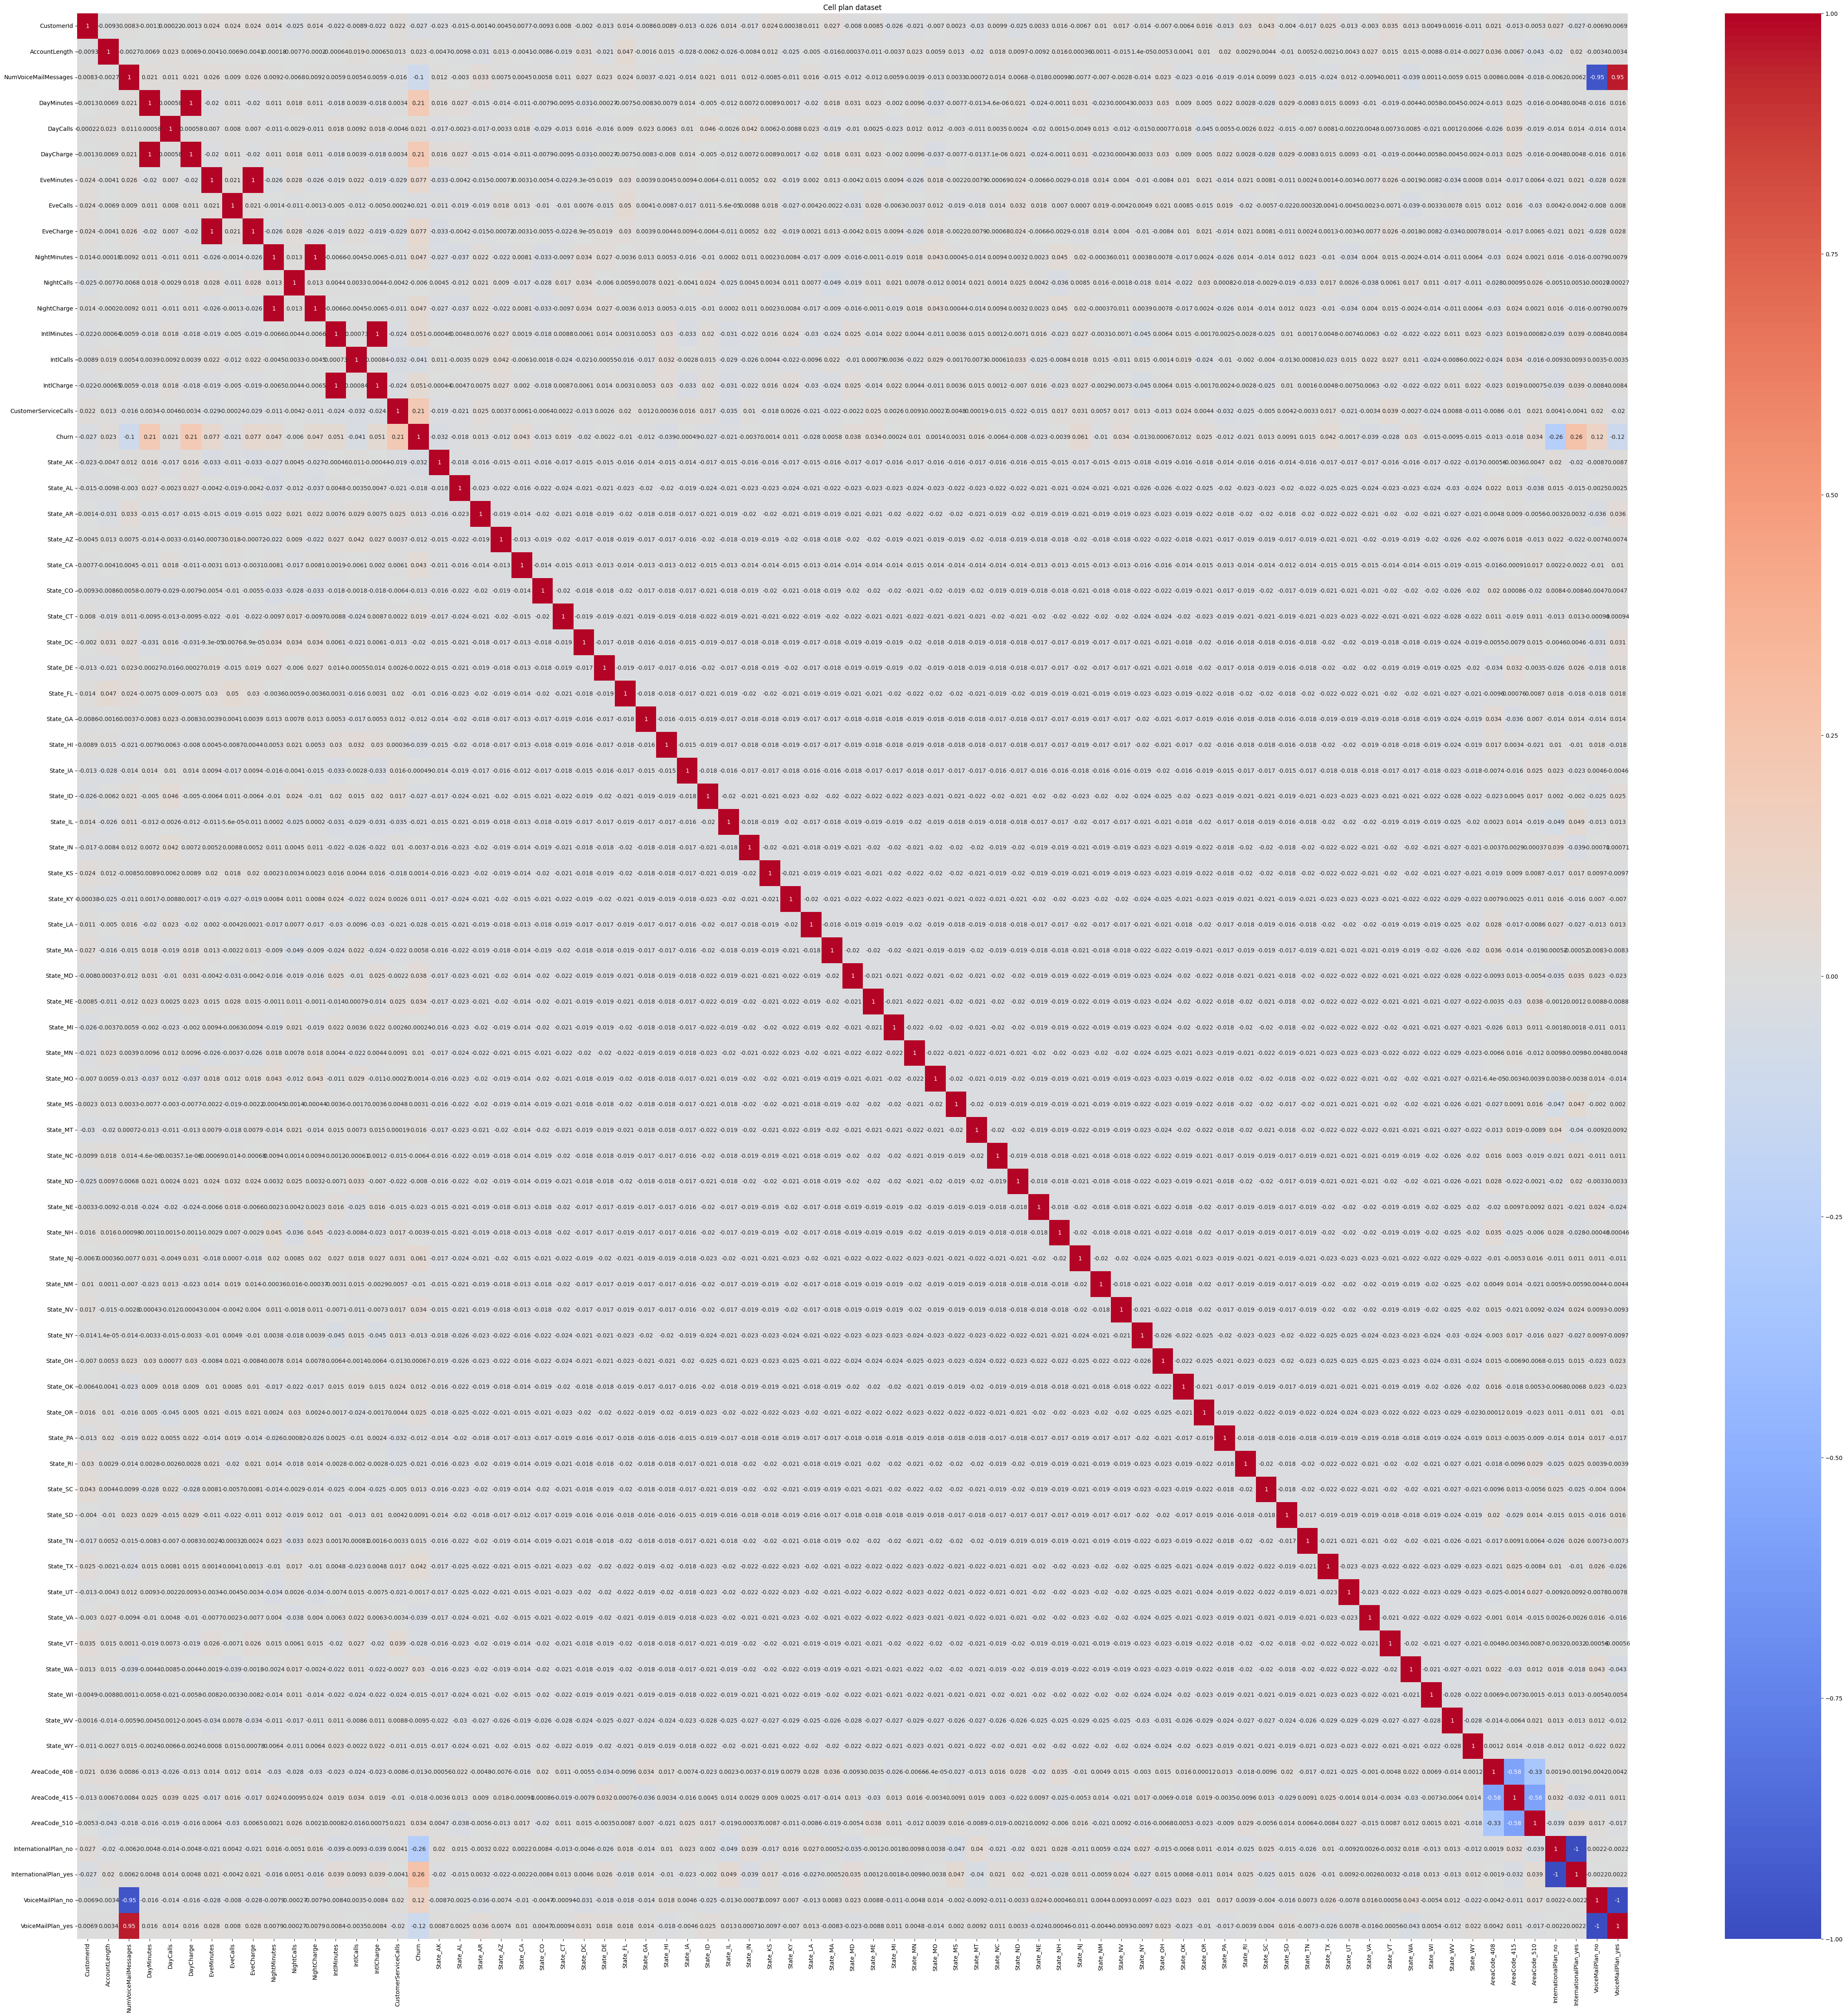

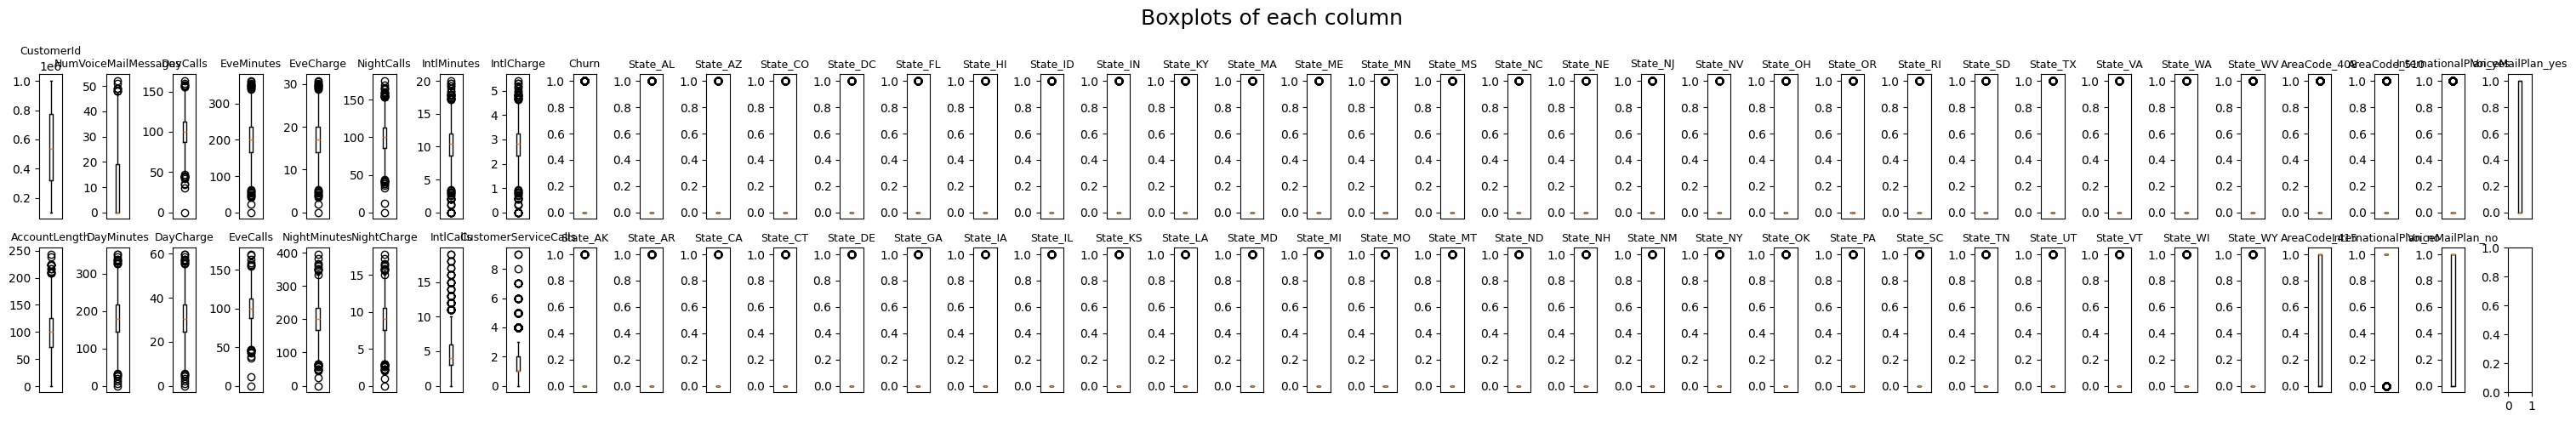

In [4]:


#sns.pairplot(train, vars=train.keys(), hue="Churn")

#plt.show()



# Modified correlation heatmap taken from the 04_correlationmap.ipynb example from canvas
# https://nmbu.instructure.com/courses/14056/files/folder/Lecture_12_Preprocessing?preview=2814845
def plot_correlation_heatmap(data, title):
    """
    Plot a correlation heatmap for a given dataset
    """
    df = pd.DataFrame(data, columns=data.keys())
    df['Churn'] = data.Churn
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
    plt.title(title)
    plt.show()

plt.figure(figsize=(60, 60))
plot_correlation_heatmap(train, 'Cell plan dataset')



fig, ax = plt.subplots(2, int(len(train.columns) / 2+ 1), figsize=(30, 5))
fig.suptitle("Boxplots of each column", fontsize=18)

delay = 0
for i, col in enumerate(train.columns):
    if i % 2 == 0:
        ax[0, i-delay].boxplot(train[col])
        ax[0, i-delay].set_title(col, fontsize=9)
        ax[0, i-delay].set_xticks([]) 
    else:
        ax[1, i-1-delay].boxplot(train[col])
        ax[1, i-1-delay].set_title(col, fontsize=9)
        ax[1, i-1-delay].set_xticks([]) 
        delay += 1


plt.tight_layout()
plt.show()

There is a strong correlation of 1 between the various times spent and the charges, and also for the boolean features created during onehotencoder.
The boxplots are as expected, and will benefit from scaling.

# Data Cleaning

In [5]:
"""
bla bla bla, we are cleaning the code yes yes, very clean indeed, so good.
"""
train = pd.read_csv("trainCA4DAT200.csv") # Importing training data again to avoid data leakage since we want onehotencoder in pipeline

print(train.shape)
print(test.shape)
train = train.dropna()
test = test.dropna()
print(train.shape)
print(test.shape)




# Remove data that is unnecessary/corelates very strongly
X = train.drop(columns=["CustomerId", "Churn", "DayMinutes", "EveMinutes", "NightMinutes", "IntlMinutes"])
y = train["Churn"]


[X_train, X_test, y_train, y_test] = \
    train_test_split(X, y,
                    test_size=0.40,
                    stratify=y,
                    random_state=1)

(3500, 21)
(1500, 20)
(3500, 21)
(1500, 20)


In [6]:
from sklearn.compose import ColumnTransformer


preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_data),
        ('numerical', StandardScaler(), X_train.drop(columns=categorical_data).columns.values)
    ]
)


pipe_svc = make_pipeline(preprocessor,
                            SVC(random_state=1, kernel='rbf', class_weight='balanced'))    # Uses kernel 'rbf'

pipe_rf = make_pipeline(preprocessor,
                            RandomForestClassifier(max_depth=4, random_state=1))

pipe_kn = make_pipeline(preprocessor,
                        PCA(n_components=5),
                            KNeighborsClassifier())



pipe_lr = make_pipeline(preprocessor,
                        PCA(n_components=5),
                        LogisticRegression(random_state=1, penalty='l2', class_weight='balanced'))

test_grid = {"logisticregression__C": [0.001, 0.01, 1, 10, 100]}


test_gs = GridSearchCV(estimator=pipe_lr,
                       param_grid=test_grid,
                       scoring='f1_macro',
                       cv= StratifiedKFold(10, shuffle=True, random_state=1),
                       n_jobs=-1)


test_gs.fit(X_train, y_train)
print(test_gs.best_score_)
print(test_gs.best_estimator_)
y_pred = test_gs.best_estimator_.predict(X_test)

0.5325796174826537
Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['State', 'AreaCode',
                                                   'InternationalPlan',
                                                   'VoiceMailPlan']),
                                                 ('numerical', StandardScaler(),
                                                  array(['AccountLength', 'NumVoiceMailMessages', 'DayCalls', 'DayCharge',
       'EveCalls', 'EveCharge', 'NightCalls', 'NightCharge', 'IntlCalls',
       'IntlCharge', 'CustomerServiceCalls'], dtype=object))])),
                ('pca', PCA(n_components=5)),
                ('logisticregression',
                 LogisticRegression(C=1, class_weight='balanced',
                                    random_state=1))])


# bla bla bla bla making pipelines, cleaning pipes, chimney pipes

In [7]:
"""
The task is to make at two pipelienes
    at least one must use some sort of dimension reduction
    one must use regularization
    one must use a kernel
"""

pipe_svc = make_pipeline(preprocessor,
                            SVC(random_state=1, kernel='rbf', class_weight='balanced'))    # Uses kernel 'rbf'

pipe_rf = make_pipeline(preprocessor,
                            RandomForestClassifier(n_estimators=500, random_state=1))

pipe_kn = make_pipeline(preprocessor,
                        PCA(n_components=5),
                            KNeighborsClassifier())



pipe_lr = make_pipeline(preprocessor,
                        PCA(n_components=5),
                        LogisticRegression(random_state=1, penalty='l2', class_weight='balanced'))



In [8]:
cross_validation = StratifiedKFold(10, shuffle=True, random_state=1)

#cross_validation.split(X, y)
from sklearn.model_selection import GridSearchCV

# SVC grid
svc_grid = {"svc__C": [0.1, 1, 10, 100],
            "svc__gamma": [0.001, 0.01, 0.1, "scale"]}

# Linear Regression grid
lr_grid = {"pca__n_components": [4, 8, 12, None], 
            "logisticregression__penalty": ["l1", "l2"], 
            "logisticregression__C": [0.001, 0.01, 1, 10, 100]}

# RandomForest grid
rf_grid = { "randomforestclassifier__max_depth": [None, 5, 10, 15, 20, 25, 30],
            "randomforestclassifier__min_samples_leaf": [1, 3, 5],
            "randomforestclassifier__class_weight": [None, "balanced"]}

# KNeighbors grid
kn_grid = {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2]}



0.8171133924125862
{'svc__C': 1, 'svc__gamma': 0.1}
0.6715575022433558
{'logisticregression__C': 1, 'logisticregression__penalty': 'l2', 'pca__n_components': None}
0.8660037175377802
{'randomforestclassifier__class_weight': 'balanced', 'randomforestclassifier__max_depth': 20, 'randomforestclassifier__min_samples_leaf': 3}
0.5565719432412579
{'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'}
[[1189   13]
 [  17  181]]


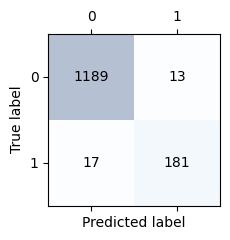

Accuracy: 0.9785714285714285
f1_score: 0.923469387755102


In [11]:

svc_gs = GridSearchCV(estimator=pipe_svc,   
                    param_grid=svc_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=-1)

svc_gs = svc_gs.fit(X, y)
print(svc_gs.best_score_)
print(svc_gs.best_params_)

lr_gs = GridSearchCV(estimator=pipe_lr,   
                    param_grid=lr_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=-1)

lr_gs = lr_gs.fit(X, y)
print(lr_gs.best_score_)
print(lr_gs.best_params_)

rf_gs = GridSearchCV(estimator=pipe_rf,   
                    param_grid=rf_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=-1)


rf_gs = rf_gs.fit(X, y)
print(rf_gs.best_score_)
print(rf_gs.best_params_)

kn_gs = GridSearchCV(estimator=pipe_kn,   
                    param_grid=kn_grid,
                    scoring='f1_macro',
                    cv=cross_validation,
                    n_jobs=-1)


kn_gs = kn_gs.fit(X, y)
print(kn_gs.best_score_)
print(kn_gs.best_params_)



y_pred = rf_gs.best_estimator_.predict(X_test)

conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_pred)
print(conf_matrix)

## Cin
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(2.5, 2.5))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i, s=conf_matrix[i, j], va='center', ha='center')

plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.tight_layout()
plt.show()

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"f1_score: {f1_score(y_test, y_pred)}")


In [14]:

test_customerId = test['CustomerId']
X = test.drop(columns='CustomerId')

y_pred = rf_gs.best_estimator_.predict(X)

submission = pd.DataFrame({'CustomerId': test_customerId,'Churn': y_pred})

submission.to_csv("submission.csv", index=False)